# Exploration : détection de data drift sur le dataset Poundbank

**Contexte.** Ce notebook s'inscrit dans le cadre d'un mémoire de recherche sur la surveillance d'un modèle de détection de fraude financière, encadré par M. Mihoubi, à partir du cas Poundbank (projet DataCamp).

**Objectif.** Comprendre les données (EDA), puis comparer trois outils open source de détection de drift — **Evidently AI**, **Alibi-Detect** et **NannyML** — afin d'identifier leurs points communs, leurs différences et l'outil le plus adapté à une architecture de monitoring en production.

**Données.** `reference.csv` (référence, janvier–octobre 2018, 50 207 lignes) et `analysis.csv` (production à surveiller, novembre 2018–juin 2019, 39 967 lignes). Neuf colonnes communes, détaillées dans `data/README.md`.

**Plan.**
1. [Configuration et chargement des données](#configuration)
2. [Analyse exploratoire des données (EDA)](#eda)
3. [Evidently AI — Data Drift preset](#evidently)
4. [Alibi-Detect — TabularDrift](#alibi-detect)
5. [NannyML — drift univarié](#nannyml-drift)
6. [NannyML — CBPE (estimation de performance sans labels)](#nannyml-cbpe)
7. [Traçabilité des versions](#versions)
8. [Bilan](#bilan)

**Avant de committer ou de partager ce notebook :** exécuter *Kernel > Restart & Run All* sur une session propre, pour garantir que les sorties affichées correspondent bien au code.

<a name="configuration"></a>
## 0. Configuration et chargement des données

In [1]:
# --- Imports ---
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Les bibliothèques de drift (dépendances numériques anciennes pour certaines)
# émettent des FutureWarning / DeprecationWarning peu utiles pour la lecture :
# on les masque, sans masquer les autres catégories de warnings.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

# --- Chemins et colonnes ---
DATA_DIR = Path.cwd()  # adapte si tes CSV sont ailleurs (ex: Path.cwd() / "data")
EDA_OUT_DIR = Path("reports/eda")
EDA_OUT_DIR.mkdir(parents=True, exist_ok=True)

TIMESTAMP_COL = "timestamp"
TARGET_COL = "is_fraud"
PREDICTION_COL = "predicted_fraud"
PREDICTED_PROBA_COL = "predicted_fraud_proba"

NUMERICAL_FEATURES = ["time_since_login_min", "transaction_amount", "user_tenure_months"]
CATEGORICAL_FEATURES = ["transaction_type", "is_first_transaction"]
FEATURE_COLUMNS = NUMERICAL_FEATURES + CATEGORICAL_FEATURES

# --- Palette et style, cohérents avec reports/eda/ (generate_eda.py) ---
COLOR_REF = "#2a78d6"     # bleu -- référence / stable
COLOR_ANA = "#eb6834"     # orange -- analyse / drift détecté
COLOR_GRID = "#d9d9d6"
COLOR_TEXT = "#3a3a38"


def style_axes(ax) -> None:
    """Applique un style cohérent à tous les graphiques du notebook."""
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(COLOR_GRID)
    ax.spines["bottom"].set_color(COLOR_GRID)
    ax.tick_params(colors=COLOR_TEXT, labelsize=9)
    ax.yaxis.grid(True, color=COLOR_GRID, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    ax.title.set_color(COLOR_TEXT)
    ax.xaxis.label.set_color(COLOR_TEXT)
    ax.yaxis.label.set_color(COLOR_TEXT)


# --- Options d'affichage pandas : lisibilité des sorties ---
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_columns", 20)

print("Configuration chargée.")

Configuration chargée.


In [2]:
reference = pd.read_csv(DATA_DIR / "reference.csv", parse_dates=[TIMESTAMP_COL])
analysis = pd.read_csv(DATA_DIR / "analysis.csv", parse_dates=[TIMESTAMP_COL])

print(f"reference.csv : {len(reference):,} lignes | {reference[TIMESTAMP_COL].min()} -> {reference[TIMESTAMP_COL].max()}")
print(f"analysis.csv  : {len(analysis):,} lignes | {analysis[TIMESTAMP_COL].min()} -> {analysis[TIMESTAMP_COL].max()}")
print(f"Taux de fraude - référence : {reference[TARGET_COL].mean():.1%} | analyse : {analysis[TARGET_COL].mean():.1%}")

reference.head()

reference.csv : 50,207 lignes | 2018-01-01 00:00:00 -> 2018-10-31 23:56:09.312000
analysis.csv  : 39,967 lignes | 2018-11-01 00:04:52.464000 -> 2019-06-30 23:56:25.296000
Taux de fraude - référence : 50.0% | analyse : 49.9%


,timestamp,time_since_login_min,transaction_amount,transaction_type,is_first_transaction,user_tenure_months,is_fraud,predicted_fraud_proba,predicted_fraud
0,2018-01-01 00:00:00.000,1.562,"3,981.100",PAYMENT,False,0.319,1.000,0.990,1
1,2018-01-01 00:08:43.152,1.658,"1,267.900",PAYMENT,False,7.391,0.000,0.070,0
2,2018-01-01 00:17:26.304,2.454,"1,984.700",CASH-IN,False,0.781,1.000,1.000,1
3,2018-01-01 00:26:09.456,2.392,"2,265.200",CASH-OUT,False,0.680,1.000,0.980,1
4,2018-01-01 00:34:52.608,2.190,"2,126.800",CASH-IN,False,8.543,1.000,0.990,1


**Constat.** Les deux jeux de données se suivent directement dans le temps, sans trou. Le taux de fraude est quasi identique entre référence et analyse (~50 % dans les deux cas), ce qui est atypique pour un cas de fraude réel (généralement très déséquilibré) : ce choix de conception du jeu de données Poundbank facilite l'apprentissage du modèle, mais doit être gardé en tête au moment d'interpréter les résultats de drift plus loin. La section suivante approfondit ce constat avant de passer à la détection de drift proprement dite.

<a name="eda"></a>
## 1. Analyse exploratoire des données (EDA)

Avant de comparer les outils de détection de drift, il est nécessaire de bien comprendre les données elles-mêmes : profilage, distributions, équilibre des classes. Cette section reprend, sous forme intégrée et commentée, les sept visualisations produites par `generate_eda.py` (le script autonome reste disponible pour régénérer ces figures en dehors du notebook, par exemple pour le mémoire).

### 1.1 Profilage — valeurs manquantes

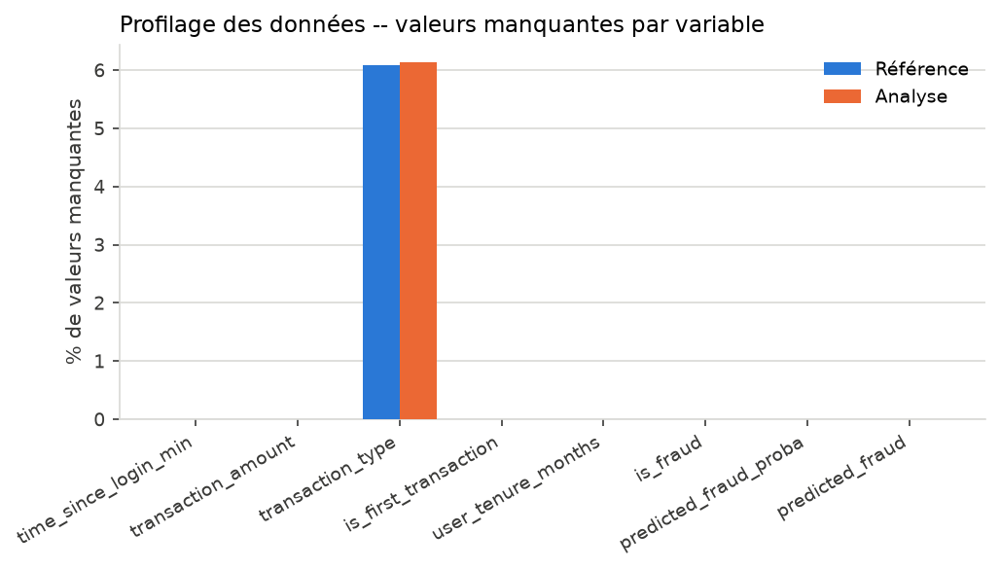

In [3]:
columns = [c for c in reference.columns if c != TIMESTAMP_COL]
ref_missing = reference[columns].isna().mean() * 100
ana_missing = analysis[columns].isna().mean() * 100

fig, ax = plt.subplots(figsize=(7, 4), dpi=150)
x = np.arange(len(columns))
width = 0.36
ax.bar(x - width / 2, ref_missing.values, width, label="Référence", color=COLOR_REF, zorder=3)
ax.bar(x + width / 2, ana_missing.values, width, label="Analyse", color=COLOR_ANA, zorder=3)
ax.set_xticks(x)
ax.set_xticklabels(columns, rotation=30, ha="right", fontsize=8)
ax.set_ylabel("% de valeurs manquantes")
ax.set_title("Profilage des données -- valeurs manquantes par variable", fontsize=11, loc="left")
ax.legend(frameon=False, fontsize=9)
style_axes(ax)
fig.tight_layout()
fig.savefig(EDA_OUT_DIR / "01_valeurs_manquantes.png")
plt.show()

**Interprétation.** Seule `transaction_type` comporte des valeurs manquantes, à un taux quasiment identique entre référence (~6,1 %) et analyse (~6,1 %). Toutes les autres variables sont complètes des deux côtés. Ce taux de manquants stable dans le temps est un premier indicateur — partiel — d'absence de dérive sur le mécanisme de collecte des données ; il faudra le confirmer avec les tests statistiques plus loin, qui portent sur la distribution des valeurs observées, pas seulement sur leur présence.

### 1.2 Distributions numériques

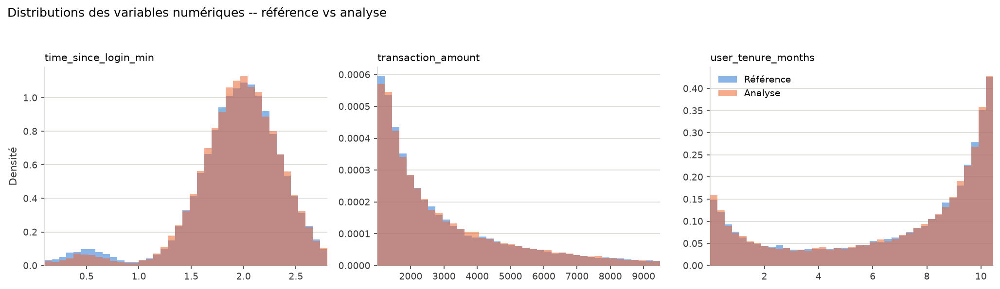

In [4]:
fig, axes = plt.subplots(1, len(NUMERICAL_FEATURES), figsize=(4.6 * len(NUMERICAL_FEATURES), 4), dpi=150)
for ax, col in zip(axes, NUMERICAL_FEATURES):
    ref_vals = reference[col].dropna()
    ana_vals = analysis[col].dropna()
    low = min(ref_vals.min(), ana_vals.min())
    high = np.percentile(np.concatenate([ref_vals, ana_vals]), 99)
    bins = np.linspace(low, high, 40)
    ax.hist(ref_vals, bins=bins, density=True, color=COLOR_REF, alpha=0.55, label="Référence", zorder=3)
    ax.hist(ana_vals, bins=bins, density=True, color=COLOR_ANA, alpha=0.55, label="Analyse", zorder=3)
    ax.set_title(col, fontsize=10, loc="left")
    ax.set_xlim(low, high)
    style_axes(ax)
axes[0].set_ylabel("Densité")
axes[-1].legend(frameon=False, fontsize=9)
fig.suptitle("Distributions des variables numériques -- référence vs analyse", fontsize=12, x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(EDA_OUT_DIR / "02_distributions_numeriques.png")
plt.show()

**Interprétation.** Les trois distributions se superposent presque parfaitement entre référence et analyse : les moyennes et écarts-types (visibles dans le tableau `describe()` ci-dessous si besoin) sont très proches (`time_since_login_min` : 1,93 vs 1,95 ; `transaction_amount` : 2 965 £ vs 2 991 £ ; `user_tenure_months` : 6,90 vs 6,88 mois). À l'œil, aucune dérive marquée n'apparaît sur ces trois variables — un résultat à confronter aux tests statistiques (KS) des sections suivantes, plus sensibles que la simple inspection visuelle.

### 1.3 Proportions catégorielles

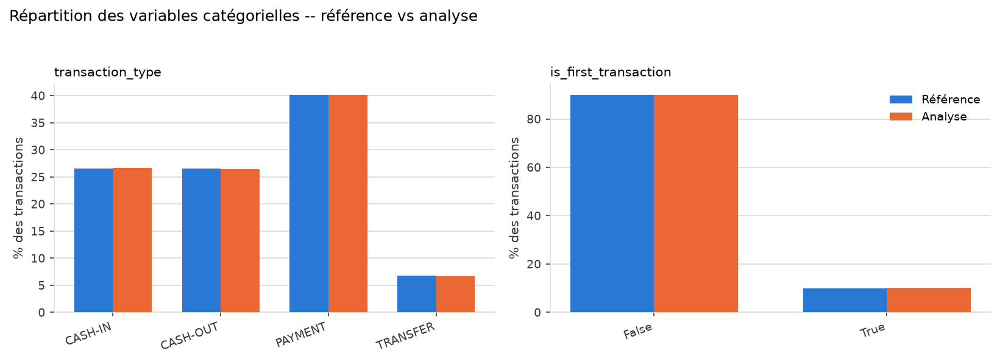

In [5]:
fig, axes = plt.subplots(1, len(CATEGORICAL_FEATURES), figsize=(5.5 * len(CATEGORICAL_FEATURES), 4), dpi=150)
for ax, col in zip(axes, CATEGORICAL_FEATURES):
    ref_props = reference[col].value_counts(normalize=True, dropna=True).sort_index()
    ana_props = analysis[col].value_counts(normalize=True, dropna=True).sort_index()
    categories = sorted(set(ref_props.index) | set(ana_props.index), key=str)
    x = np.arange(len(categories))
    width = 0.36
    ref_vals = [ref_props.get(c, 0) * 100 for c in categories]
    ana_vals = [ana_props.get(c, 0) * 100 for c in categories]
    ax.bar(x - width / 2, ref_vals, width, label="Référence", color=COLOR_REF, zorder=3)
    ax.bar(x + width / 2, ana_vals, width, label="Analyse", color=COLOR_ANA, zorder=3)
    ax.set_xticks(x)
    ax.set_xticklabels([str(c) for c in categories], rotation=20, ha="right", fontsize=8)
    ax.set_ylabel("% des transactions")
    ax.set_title(col, fontsize=10, loc="left")
    style_axes(ax)
axes[-1].legend(frameon=False, fontsize=9)
fig.suptitle("Répartition des variables catégorielles -- référence vs analyse", fontsize=12, x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(EDA_OUT_DIR / "03_proportions_categorielles.png")
plt.show()

**Interprétation.** `transaction_type` conserve une hiérarchie identique entre les deux périodes (PAYMENT ~37,7 %, CASH-IN et CASH-OUT ~25 % chacun, TRANSFER ~6,3 %), avec des écarts de moins d'un point de pourcentage sur chaque catégorie. `is_first_transaction` est également stable (10,0 % de premières transactions en référence, 10,1 % en analyse). Aucun signal de dérive catégorielle visible à ce stade.

### 1.4 Taux de fraude mensuel (label drift)

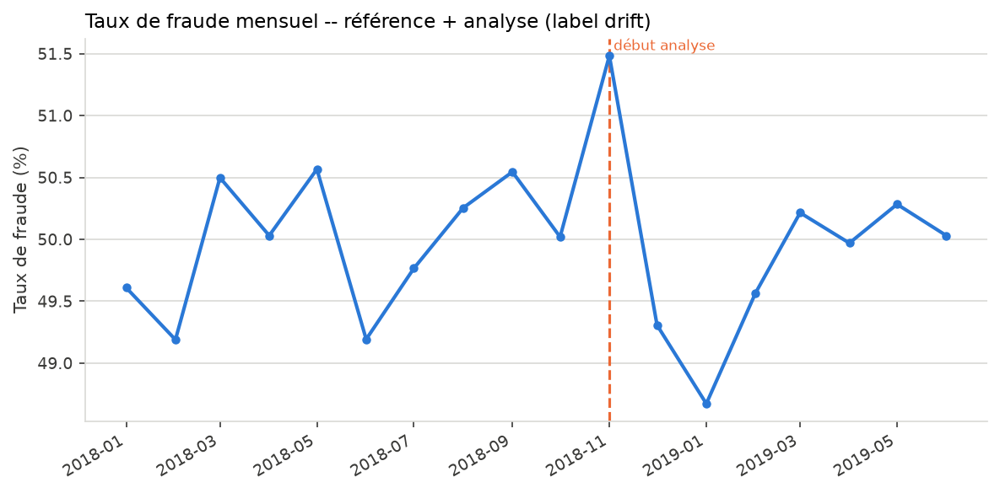

In [6]:
ref_m = reference.assign(period="Référence")
ana_m = analysis.assign(period="Analyse")
combined = pd.concat([ref_m, ana_m], ignore_index=True)
combined["month"] = combined[TIMESTAMP_COL].dt.to_period("M").dt.to_timestamp()

monthly_fraud = combined.groupby("month")[TARGET_COL].mean() * 100
boundary = ana_m[TIMESTAMP_COL].min()

fig, ax = plt.subplots(figsize=(8, 4), dpi=150)
ax.plot(monthly_fraud.index, monthly_fraud.values, color=COLOR_REF, linewidth=2, marker="o", markersize=4, zorder=3)
ax.axvline(boundary, color=COLOR_ANA, linestyle="--", linewidth=1.5, zorder=2)
ax.text(boundary, ax.get_ylim()[1], " début analyse", color=COLOR_ANA, fontsize=8, va="top")
ax.set_ylabel("Taux de fraude (%)")
ax.set_title("Taux de fraude mensuel -- référence + analyse (label drift)", fontsize=11, loc="left")
fig.autofmt_xdate(rotation=30)
style_axes(ax)
fig.tight_layout()
fig.savefig(EDA_OUT_DIR / "04_taux_fraude_mensuel.png")
plt.show()

**Interprétation.** Le taux de fraude mensuel oscille entre 48,7 % et 51,5 % sur toute la période (18 mois), sans tendance haussière ni baissière et sans rupture visible à la frontière référence/analyse (novembre 2018, ligne pointillée). ###Ce n'est pas un signal de *label drift* : la fraude reste statistiquement aussi fréquente après la mise en production qu'avant.(Appoter plus d'explications)##

### 1.5 Montant moyen de transaction mensuel

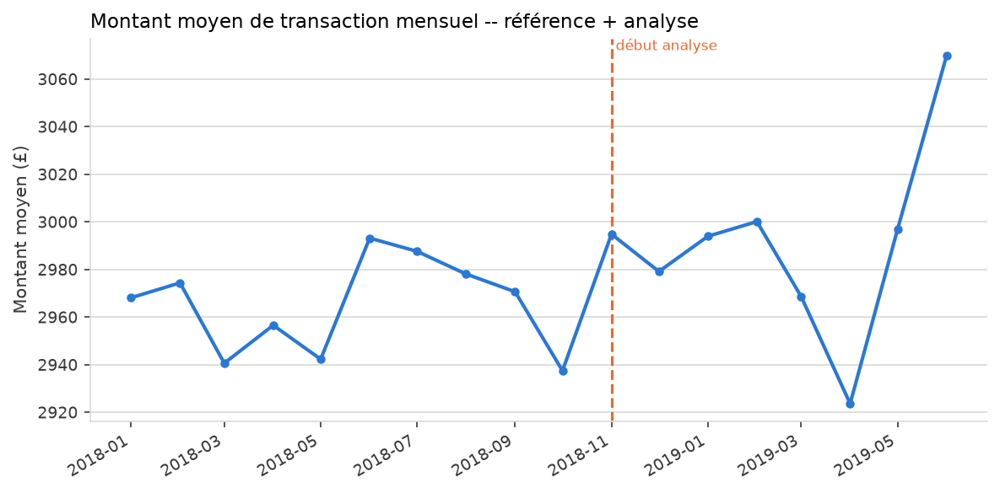

In [7]:
monthly_amount = combined.groupby("month")["transaction_amount"].mean()

fig, ax = plt.subplots(figsize=(8, 4), dpi=150)
ax.plot(monthly_amount.index, monthly_amount.values, color=COLOR_REF, linewidth=2, marker="o", markersize=4, zorder=3)
ax.axvline(boundary, color=COLOR_ANA, linestyle="--", linewidth=1.5, zorder=2)
ax.text(boundary, ax.get_ylim()[1], " début analyse", color=COLOR_ANA, fontsize=8, va="top")
ax.set_ylabel("Montant moyen (£)")
ax.set_title("Montant moyen de transaction mensuel -- référence + analyse", fontsize=11, loc="left")
fig.autofmt_xdate(rotation=30)
style_axes(ax)
fig.tight_layout()
fig.savefig(EDA_OUT_DIR / "05_montant_moyen_mensuel.png")
plt.show()

**Interprétation.** Le montant moyen mensuel varie peu (entre 2 924 £ et 3 070 £ sur 18 mois), sans rupture nette à la frontière référence/analyse. Le seul mois qui se démarque légèrement est le dernier (juin 2019, ~3 070 £, le plus élevé de la série) : à surveiller dans les sections de drift plus loin, sans que cet écart isolé ne suffise à conclure à une tendance installée.## (Esplanabilité)##

### 1.6 Équilibre des classes

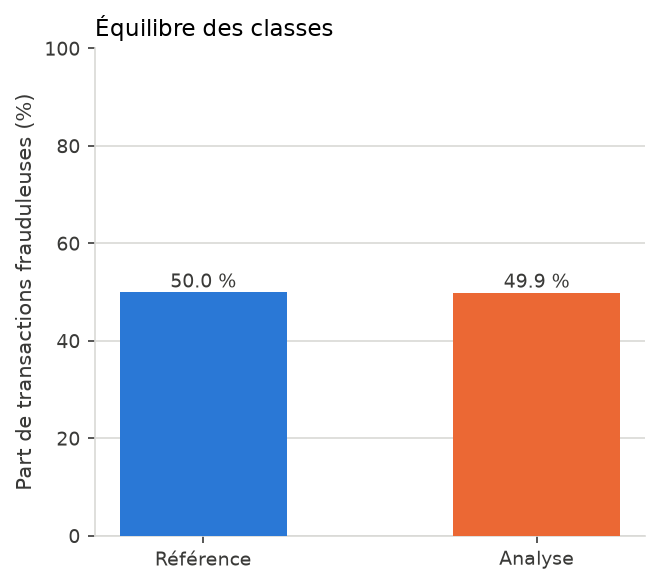

In [8]:
ref_rate = reference[TARGET_COL].mean() * 100
ana_rate = analysis[TARGET_COL].mean() * 100

fig, ax = plt.subplots(figsize=(4.5, 4), dpi=150)
bars = ax.bar(["Référence", "Analyse"], [ref_rate, ana_rate], color=[COLOR_REF, COLOR_ANA], width=0.5, zorder=3)
for bar, val in zip(bars, [ref_rate, ana_rate]):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 1, f"{val:.1f} %", ha="center", fontsize=9, color=COLOR_TEXT)
ax.set_ylim(0, 100)
ax.set_ylabel("Part de transactions frauduleuses (%)")
ax.set_title("Équilibre des classes", fontsize=11, loc="left")
style_axes(ax)
fig.tight_layout()
fig.savefig(EDA_OUT_DIR / "06_equilibre_classes.png")
plt.show()

**Interprétation.** Le dataset est quasi parfaitement équilibré (~50/50) dans les deux fichiers, à comparer aux cas réels de détection de fraude où la classe positive représente typiquement moins de 1 % des transactions. Cet équilibre artificiel facilite l'entraînement du modèle mais limite la portée des conclusions de ce mémoire pour un déploiement en conditions réelles fortement déséquilibrées — point à mentionner explicitement dans les limites du travail.

### 1.7 Distribution des probabilités prédites

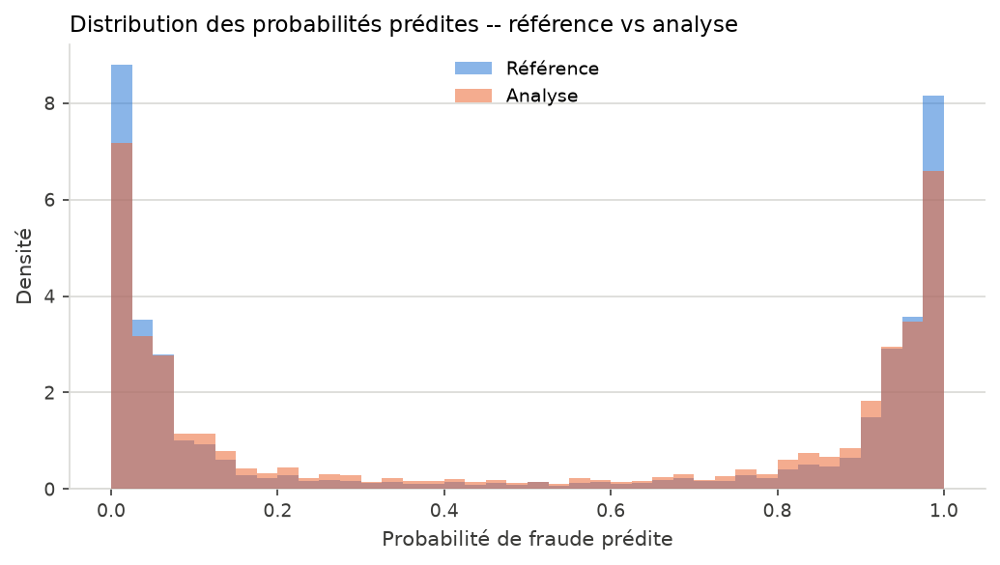

In [9]:
fig, ax = plt.subplots(figsize=(7, 4), dpi=150)
bins = np.linspace(0, 1, 41)
ax.hist(reference[PREDICTED_PROBA_COL], bins=bins, density=True, color=COLOR_REF, alpha=0.55, label="Référence", zorder=3)
ax.hist(analysis[PREDICTED_PROBA_COL], bins=bins, density=True, color=COLOR_ANA, alpha=0.55, label="Analyse", zorder=3)
ax.set_xlabel("Probabilité de fraude prédite")
ax.set_ylabel("Densité")
ax.set_title("Distribution des probabilités prédites -- référence vs analyse", fontsize=11, loc="left")
ax.legend(frameon=False, fontsize=9)
style_axes(ax)
fig.tight_layout()
fig.savefig(EDA_OUT_DIR / "07_distribution_probabilites_predites.png")
plt.show()

**Interprétation.** La distribution est bimodale (le modèle est plutôt confiant : peu de probabilités autour de 0,5, davantage proches de 0 ou de 1), et cette forme se retrouve à l'identique entre référence et analyse. Combiné au taux de prédictions positives quasi stable (48,5 % dans les deux fichiers), rien n'indique ici un recalibrage du modèle ni un changement de comportement du score entre les deux périodes.

**Synthèse de l'EDA.** Sur les sept angles examinés, aucun signal fort de dérive n'apparaît à l'inspection visuelle : proportions, distributions et taux de fraude restent stables dans le temps. Cela ne dispense pas des tests statistiques formels (sections suivantes), plus sensibles à des écarts fins que l'œil ne détecte pas forcément, notamment sur `transaction_amount` dont la variance interne est élevée.

<a name="evidently"></a>
## 2. Evidently AI — Data Drift preset

Evidently sélectionne automatiquement le test statistique adapté à chaque colonne (test de Kolmogorov-Smirnov pour le numérique, Chi-deux pour le catégoriel, ou PSI selon la taille de l'échantillon) et compare `reference` à `analysis` colonne par colonne.

In [10]:
from evidently import Report
from evidently.presets import DataDriftPreset

report = Report(metrics=[DataDriftPreset()])
evidently_result = report.run(
    reference_data=reference[FEATURE_COLUMNS],
    current_data=analysis[FEATURE_COLUMNS],
)

evidently_result.save_html("evidently_data_drift.html")
print("Rapport HTML généré : evidently_data_drift.html (ouvre-le dans un navigateur pour le détail interactif)")

Rapport HTML généré : evidently_data_drift.html (ouvre-le dans un navigateur pour le détail interactif)


In [11]:
# Aperçu direct dans le notebook (Jupyter affiche le rapport Evidently inline)
evidently_result

**À noter en consultant le rapport.** Repérer en particulier : le nombre de colonnes signalées en drift sur le total, et si les variables concernées recoupent celles détectées par Alibi-Detect et NannyML plus bas — c'est cette convergence (ou son absence) entre outils qui sera discutée dans le bilan. Au vu de l'EDA (section 1), on s'attend à peu ou pas de drift signalé ici.

<a name="alibi-detect"></a>
## 3. Alibi-Detect — TabularDrift (KS + Chi-deux, correction FDR)

Test de Kolmogorov-Smirnov sur chaque variable numérique, Chi-deux sur chaque variable catégorielle, avec une **correction pour tests multiples (FDR — False Discovery Rate)**, nécessaire car cinq variables sont testées en parallèle : sans correction, le risque de détecter un faux positif augmente avec le nombre de tests.(Notions mathématiques)

In [12]:
from alibi_detect.cd import TabularDrift

ref = reference[FEATURE_COLUMNS].copy()
cur = analysis[FEATURE_COLUMNS].copy()

categories_per_feature = {}
for col in CATEGORICAL_FEATURES:
    ref[col] = ref[col].astype("category")
    categories = ref[col].cat.categories
    cur[col] = cur[col].astype(pd.CategoricalDtype(categories=categories))
    ref[col] = ref[col].cat.codes
    cur[col] = cur[col].cat.codes
    categories_per_feature[FEATURE_COLUMNS.index(col)] = len(categories)

x_ref = ref.to_numpy(dtype=np.float64)
x_cur = cur.to_numpy(dtype=np.float64)

alibi_detector = TabularDrift(
    x_ref=x_ref,
    p_val=0.05,
    categories_per_feature=categories_per_feature,
    correction="fdr",
)
alibi_prediction = alibi_detector.predict(x_cur, drift_type="feature")

alibi_df = pd.DataFrame([
    {
        "feature": col,
        "type": "categorielle" if col in CATEGORICAL_FEATURES else "numerique",
        "drift_detecte": bool(alibi_prediction["data"]["is_drift"][i]),
        "p_value": float(alibi_prediction["data"]["p_val"][i]),
    }
    for i, col in enumerate(FEATURE_COLUMNS)
]).sort_values("p_value")

dataset_drift = bool(alibi_prediction["data"]["is_drift"].any())
print(f"Dataset drift (au moins une variable en drift, seuil p < 0.05 après correction FDR) : {dataset_drift}")
alibi_df.style.format({"p_value": "{:.4f}"}).background_gradient(
    subset=["p_value"], cmap="RdYlGn", vmin=0, vmax=0.10
)

None of PyTorch, TensorFlow >= 2.0, or Flax have been found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


Dataset drift (au moins une variable en drift, seuil p < 0.05 après correction FDR) : True


,feature,type,drift_detecte,p_value
0,time_since_login_min,numerique,True,0.0000
1,transaction_amount,numerique,True,0.0085
4,is_first_transaction,categorielle,False,0.6197
2,user_tenure_months,numerique,False,0.6303
3,transaction_type,categorielle,False,0.9411


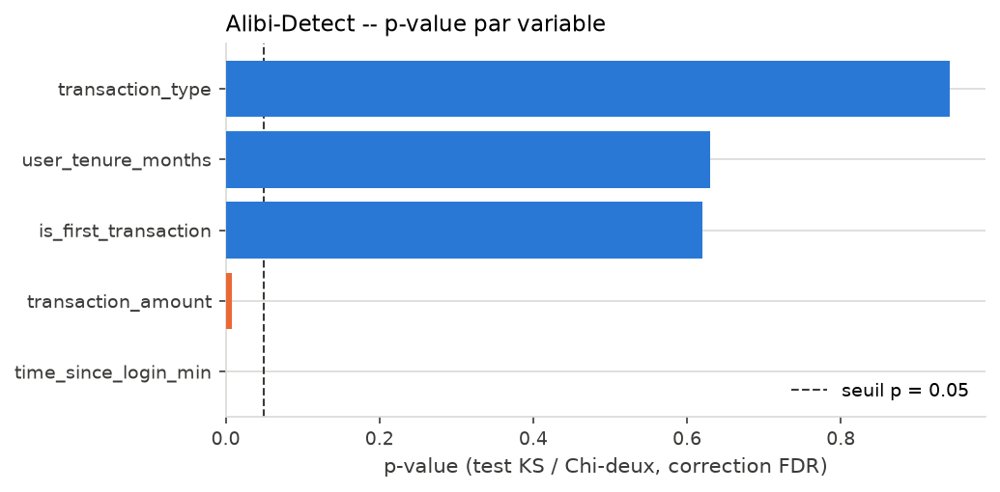

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.5), dpi=150)
plot_df = alibi_df.sort_values("p_value", ascending=True)
colors = [COLOR_ANA if drift else COLOR_REF for drift in plot_df["drift_detecte"]]
ax.barh(plot_df["feature"], plot_df["p_value"], color=colors, zorder=3)
ax.axvline(0.05, color=COLOR_TEXT, linestyle="--", linewidth=1, label="seuil p = 0.05")
ax.set_xlabel("p-value (test KS / Chi-deux, correction FDR)")
ax.set_title("Alibi-Detect -- p-value par variable", fontsize=11, loc="left")
ax.legend(frameon=False, fontsize=9)
style_axes(ax)
fig.tight_layout()
plt.show()

**Lecture du graphique.** Les barres orange (sous le seuil pointillé) signalent une variable pour laquelle Alibi-Detect rejette l'hypothèse de stabilité de la distribution entre référence et analyse. 

##Nous allons compléter cette cellule avec la liste des variables effectivement en drift une fois le notebook exécuté, et vérifier si Evidently (section 2) pointe vers les mêmes variables.##

<a name="nannyml-drift"></a>
## 4. NannyML — drift univarié

Approche proche d'Alibi-Detect sur le plan statistique (KS, Chi-deux), mais NannyML gère nativement le découpage temporel (*chunking*) : le drift est calculé par tranche de temps plutôt que sur l'ensemble de la période d'analyse en un bloc, ce qui permet de repérer à partir de quel moment une dérive apparaît.

In [14]:
import nannyml as nml

univariate_calc = nml.UnivariateDriftCalculator(
    column_names=FEATURE_COLUMNS,
    continuous_methods=["kolmogorov_smirnov"],
    categorical_methods=["chi2"],
    timestamp_column_name=TIMESTAMP_COL,
)
univariate_calc.fit(reference)
drift_results = univariate_calc.calculate(analysis)
drift_df = drift_results.to_df()
drift_df.head()

chunk                                                            \
           chunk                                                             
             key chunk_index start_index end_index              start_date   
0       [0:5019]           0           0      5019 2018-01-01 00:00:00.000   
1   [5020:10039]           1        5020     10039 2018-01-31 09:30:23.040   
2  [10040:15059]           2       10040     15059 2018-03-02 19:00:46.080   
3  [15060:20079]           3       15060     20079 2018-04-02 04:31:09.120   
4  [20080:25099]           4       20080     25099 2018-05-02 14:01:32.160   

                                     time_since_login_min                  \
                                       kolmogorov_smirnov                   
                 end_date     period                value upper_threshold   
0 2018-01-31 09:21:39.888  reference                0.009           0.277   
1 2018-03-02 18:52:02.928  reference                0.006           0.277   
2 2018-04-02 04:22:25.968  reference                0.006           0.277   
3 2018-05-02 13:52:49.008  reference                0.011           0.277   
4 2018-06-01 23:23:12.048  reference                0.009           0.277   

                   ... user_tenure_months        is_first_transaction  \
                   ... kolmogorov_smirnov                        chi2   
  lower_threshold  ...    lower_threshold  alert                value   
0            None  ...               None  False                0.030   
1            None  ...               None  False                0.196   
2            None  ...               None  False                0.002   
3            None  ...               None  False                0.388   
4            None  ...               None  False                1.149   

                                         transaction_type                  \
                                                     chi2                   
  upper_threshold lower_threshold  alert            value upper_threshold   
0            None            None  False            5.106            None   
1            None            None  False            0.467            None   
2            None            None  False            0.547            None   
3            None            None  False            2.877            None   
4            None            None  False            1.756            None   

                          
                          
  lower_threshold  alert  
0            None  False  
1            None  False  
2            None  False  
3            None  False  
4            None  False  

[5 rows x 27 columns]

In [15]:
drift_results.plot(kind="drift")

**Lecture du graphique.** Chaque point représente une tranche temporelle (chunk) de la période d'analyse. Une ligne qui s'écarte de la zone de référence, ou qui franchit le seuil d'alerte, indique une dérive localisée dans le temps — information que les tests globaux (Evidently, Alibi-Detect) ne donnent pas directement. ##Nous allons noter à partir de quelle période les éventuelles dérives apparaissent, notamment sur `transaction_amount` en juin 2019 (cf. section 1.5).##

<a name="nannyml-cbpe"></a>
## 5. NannyML — CBPE : estimation de performance sans les vrais labels

Le seul des trois outils qui estime la performance du modèle (ROC-AUC, precision, recall, F1) en production **sans disposer des vrais labels de fraude**, à partir des probabilités prédites par le modèle. Deux limites à garder en tête : cette estimation nécessite des probabilités bien calibrées, et elle n'est fiable que sous *data drift* — pas sous *concept drift* (changement de la relation entre variables et label).

In [16]:
estimator = nml.CBPE(
    problem_type="classification_binary",
    y_pred_proba=PREDICTED_PROBA_COL,
    y_pred=PREDICTION_COL,
    y_true=TARGET_COL,
    timestamp_column_name=TIMESTAMP_COL,
    metrics=["roc_auc", "precision", "recall", "f1"],
    chunk_period="M",
)
estimator.fit(reference)
performance_results = estimator.estimate(analysis)
performance_df = performance_results.to_df()
performance_df.head()

chunk                                               \
       key chunk_index start_index end_index start_date   
0  2018-01           0           0      5119 2018-01-01   
1  2018-02           1        5120      9744 2018-02-01   
2  2018-03           2        9745     14863 2018-03-01   
3  2018-04           3       14864     19818 2018-04-01   
4  2018-05           4       19819     24938 2018-05-01   

                                           roc_auc                          \
                       end_date     period   value sampling_error realized   
0 2018-01-31 23:59:59.999999999  reference   0.971          0.002    0.976   
1 2018-02-28 23:59:59.999999999  reference   0.971          0.002    0.969   
2 2018-03-31 23:59:59.999999999  reference   0.971          0.002    0.971   
3 2018-04-30 23:59:59.999999999  reference   0.971          0.002    0.972   
4 2018-05-31 23:59:59.999999999  reference   0.971          0.002    0.969   

   ...          recall           f1                          \
   ... lower_threshold  alert value sampling_error realized   
0  ...           0.918  False 0.943          0.006    0.946   
1  ...           0.918  False 0.941          0.007    0.938   
2  ...           0.918  False 0.942          0.006    0.944   
3  ...           0.918  False 0.943          0.006    0.943   
4  ...           0.918  False 0.943          0.006    0.938   

                                                                       \
  upper_confidence_boundary lower_confidence_boundary upper_threshold   
0                     0.962                     0.924           0.950   
1                     0.961                     0.921           0.950   
2                     0.961                     0.923           0.950   
3                     0.963                     0.924           0.950   
4                     0.962                     0.924           0.950   

                          
  lower_threshold  alert  
0           0.935  False  
1           0.935  False  
2           0.935  False  
3           0.935  False  
4           0.935  False  

[5 rows x 39 columns]

In [17]:
performance_results.plot()

**Lecture du graphique.** Puisque `is_fraud` est disponible dans `analysis.csv` (contrairement à une vraie mise en production), on peut comparer la performance *estimée* par CBPE à la performance *réelle*, calculable directement à partir des labels -- c'est l'occasion de valider la fiabilité de l'estimation sur ce jeu de données avant de s'y fier en conditions réelles (voir `docs/etat-de-l-art.md`).

<a name="versions"></a>
## 6. Traçabilité des versions

In [18]:
import sys
from importlib.metadata import version

print(f"Python        : {sys.version.split()[0]}")
for package in ["pandas", "numpy", "scipy", "evidently", "alibi-detect", "nannyml"]:
    try:
        print(f"{package:<14}: {version(package)}")
    except Exception:
        print(f"{package:<14}: non installé dans cet environnement")

Python        : 3.11.16
pandas        : 2.3.3
numpy         : 1.26.4
scipy         : 1.17.1
evidently     : 0.7.23
alibi-detect  : 0.13.0
nannyml       : 0.13.1


<a name="bilan"></a>
## 7. Bilan

**Constats de l'EDA (section 1).**
Sur les sept angles d'analyse (valeurs manquantes, distributions numériques, proportions catégorielles, taux de fraude mensuel, montant moyen mensuel, équilibre des classes, distribution des probabilités prédites), aucun signal fort de dérive n'apparaît à l'inspection visuelle. Le taux de fraude mensuel reste dans une fourchette stable (48,7 % à 51,5 %) sur toute la période, sans rupture nette ; le seul point de vigilance est le montant moyen de juin 2019, légèrement supérieur au reste de la série.

**Constats des tests de drift.**

| Variable | Evidently (magnitude, Wasserstein/JS) | Alibi-Detect (p-value, FDR) | NannyML (chunké, temporel) |
|---|---|---|---|
| `time_since_login_min` | Pas de drift (0,0475) | **Drift** (p ≈ 0) | Alerte en dernier segment (0,2842) ; hausse progressive dès mars 2019 |
| `transaction_amount` | Pas de drift (0,0146) | **Drift** (p = 0,0085) | Pas d'alerte ; hausse dès mai 2019 (0,2725 en fin de période, sous le seuil) |
| `user_tenure_months` | Pas de drift (0,0055) | Pas de drift (p = 0,63) | Alerte isolée sur le dernier segment (0,3235) |
| `transaction_type` | Pas de drift (0,0020) | Pas de drift (p = 0,94) | Pas d'alerte |
| `is_first_transaction` | Pas de drift (0,0012) | Pas de drift (p = 0,62) | 1 alerte isolée (déc. 2018), non reproduite |

**Interprétation.**
Les trois outils ne se contredisent pas par erreur : ils répondent à des questions différentes. Alibi-Detect, avec un test global sur ~40 000 observations, détecte une significativité statistique sur `time_since_login_min` et `transaction_amount` même pour un écart réel modeste. Evidently, en mesurant la magnitude (Wasserstein/Jensen-Shannon) sur l'ensemble de la période en une seule fois, moyenne les segments stables et les segments dérivants et ne signale rien. NannyML, en découpant le temps, est seul à révéler la dynamique réelle : la dérive de `time_since_login_min` n'est pas constante, elle s'installe progressivement à partir de mars 2019 et s'intensifie en fin de période ; celle de `user_tenure_months` est un épisode localisé sur le seul dernier segment, dilué à l'insignifiance dans les tests globaux. Les variables catégorielles, elles, convergent vers l'absence de dérive structurelle sur les trois outils ; l'alerte isolée de NannyML sur `is_first_transaction` (décembre 2018, non reproduite) s'interprète comme du bruit statistique plutôt que comme un signal réel.

**Lien avec la performance.**
Le CBPE (section 6) montre une dégradation simultanée des quatre métriques (ROC AUC, Precision, Recall, F1) à partir d'**avril 2019**, stable à ce niveau dégradé jusqu'en juin — avec le recul relatif le plus marqué sur le Recall (≈0,929 → ≈0,885), la métrique la plus sensible au risque métier. Ce point précède de deux mois le franchissement du seuil d'alerte de drift univarié par seuil simple (juin 2019), mais coïncide avec le début de la hausse continue de la statistique KS de `time_since_login_min` observée par NannyML dès mars 2019. Le taux de fraude mensuel ne présentant pas de rupture au même moment, un simple décalage du taux de base (label drift) est peu probable comme explication. Ce rapprochement temporel constitue une hypothèse argumentée en faveur d'un effet de type *concept drift* porté par la dérive progressive d'une covariable — **pas une preuve causale** : la confirmer nécessiterait une analyse d'attribution (SHAP), non réalisable sans accès au modèle réel. Analyse complète dans `analyse-comparative-outils-drift.md`.

**Limites de cette exploration.**
CBPE reste valide sous data drift mais pas sous concept drift avéré — point non tranché ici. La correction FDR appliquée par Alibi-Detect, bien que nécessaire pour limiter les faux positifs sur des tests multiples, peut aussi masquer un signal faible mais réel si on ne croise pas avec une approche chunkée. Le jeu de données présente un taux de fraude équilibré à ~50 %, atypique en conditions réelles où la fraude représente généralement moins de 1 % des transactions — un point à rappeler dans toute généralisation des seuils proposés.

**Prochaine étape.**
Cette mise en relation (drift observé ↔ dégradation de performance ↔ recommandation opérationnelle) constitue le cœur du mémoire. Une proposition de dispositif d'alerte à deux niveaux (tendance chunkée + performance CBPE) et de stratégie de réentraînement, construite directement sur ces constats, est détaillée dans `architecture-monitoring-alertes-retraining.md`. Prochaine étape : faire évoluer ce prototype batch vers une architecture de monitoring temps réel (voir `docs/architecture-cible.md`).